In [ ]:
# =========================
# CONFIG
# =========================

FRAME_NAME = "frame_1180"
FRAME_ZIP = "/content/images80.zip"

RESOLUTION = 4
ITERATIONS = 15000
TEST_COUNT = 5

# paper-style alpha loss weight
LAMBDA_ALPHA = 0.01

# experiment name
EXP_NAME = "frame_1180_paper_alpha_loss"

print("FRAME_NAME   =", FRAME_NAME)
print("ITERATIONS   =", ITERATIONS)
print("LAMBDA_ALPHA =", LAMBDA_ALPHA)
print("EXP_NAME     =", EXP_NAME)

FRAME_NAME   = frame_1180
ITERATIONS   = 15000
LAMBDA_ALPHA = 0.01
EXP_NAME     = frame_1180_paper_alpha_loss


In [ ]:
import zipfile
import shutil
from pathlib import Path

zip_path = Path(FRAME_ZIP)
extract_root = Path("/content/_tmp_extract")
data_root = Path("/content/data")
frame_root = data_root / FRAME_NAME

if extract_root.exists():
    shutil.rmtree(extract_root)
extract_root.mkdir(parents=True, exist_ok=True)

data_root.mkdir(parents=True, exist_ok=True)
if frame_root.exists():
    shutil.rmtree(frame_root)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_root)

candidates = [p for p in extract_root.rglob(FRAME_NAME) if p.is_dir()]
if not candidates:
    raise FileNotFoundError(f"Could not find folder named {FRAME_NAME} inside {FRAME_ZIP}")

src_frame = candidates[0]
shutil.move(str(src_frame), str(frame_root))

print("Final dataset root:", frame_root)
for p in sorted(frame_root.iterdir()):
    print(" -", p)

Final dataset root: /content/data/frame_1180
 - /content/data/frame_1180/.DS_Store
 - /content/data/frame_1180/colmap.txt
 - /content/data/frame_1180/images
 - /content/data/frame_1180/masks_binary
 - /content/data/frame_1180/sparse


In [ ]:
from pathlib import Path
import shutil

frame_root = Path(f"/content/data/{FRAME_NAME}")
sparse_root = frame_root / "sparse"

if not sparse_root.exists():
    raise FileNotFoundError("No sparse directory found")

if not (sparse_root / "0").exists():
    zero_dir = sparse_root / "0"
    zero_dir.mkdir(exist_ok=True)
    for p in list(sparse_root.iterdir()):
        if p.name == "0":
            continue
        shutil.move(str(p), str(zero_dir / p.name))
    print("✅ Created sparse/0")
else:
    print("✅ sparse/0 already exists")

gt_src = frame_root / "masks_binary"
gt_dst = frame_root / "masks_binary_gt"
if gt_src.exists() and not gt_dst.exists():
    shutil.move(str(gt_src), str(gt_dst))
    print("✅ Moved masks_binary -> masks_binary_gt")
elif gt_dst.exists():
    print("✅ masks_binary_gt already exists")
else:
    raise FileNotFoundError("No masks_binary found")

print("Done")

✅ sparse/0 already exists
✅ Moved masks_binary -> masks_binary_gt
Done


In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import shutil
import os

frame_root = Path(f"/content/data/{FRAME_NAME}")
images_dir = frame_root / "images"

ones_dst = frame_root / "masks_binary_ones"
if ones_dst.exists():
    shutil.rmtree(ones_dst)
ones_dst.mkdir(parents=True, exist_ok=True)

for img_path in sorted(images_dir.iterdir()):
    if img_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
        continue
    img = Image.open(img_path)
    ones = np.ones((img.size[1], img.size[0]), dtype=np.uint8) * 255
    Image.fromarray(ones).save(ones_dst / f"{img_path.stem}_mask_ground_truth.png")

active = frame_root / "masks_binary_active"
if active.exists() or active.is_symlink():
    active.unlink() if active.is_symlink() else shutil.rmtree(active)

os.symlink(frame_root / "masks_binary_gt", active, target_is_directory=True)

print("✅ masks_binary_ones created")
print("✅ masks_binary_active ->", active.resolve())

/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))


✅ masks_binary_ones created
✅ masks_binary_active -> /content/data/frame_1180/masks_binary_gt


In [ ]:
%%bash
set -e

rm -rf /content/Wheat-3DGS

git clone https://github.com/zdwww/Wheat-3DGS.git /content/Wheat-3DGS
cd /content/Wheat-3DGS

git submodule sync --recursive
git submodule update --init --recursive

Submodule path 'submodules/diff-gaussian-rasterization': checked out '8829d14f814fccdaf840b7b0f3021a616583c0a1'
Submodule path 'submodules/diff-gaussian-rasterization/third_party/glm': checked out '5c46b9c07008ae65cb81ab79cd677ecc1934b903'
Submodule path 'submodules/flashsplat-rasterization': checked out 'b7698d2733fcecef2f2e46febdbf8e93735d2a00'
Submodule path 'submodules/simple-knn': checked out '86710c2d4b46680c02301765dd79e465819c8f19'


Cloning into '/content/Wheat-3DGS'...
Submodule 'submodules/diff-gaussian-rasterization' (https://github.com/ashawkey/diff-gaussian-rasterization.git) registered for path 'submodules/diff-gaussian-rasterization'
Submodule 'submodules/flashsplat-rasterization' (https://github.com/florinshen/flashsplat-rasterization.git) registered for path 'submodules/flashsplat-rasterization'
Submodule 'submodules/simple-knn' (https://gitlab.inria.fr/bkerbl/simple-knn.git) registered for path 'submodules/simple-knn'
Cloning into '/content/Wheat-3DGS/submodules/diff-gaussian-rasterization'...
Cloning into '/content/Wheat-3DGS/submodules/flashsplat-rasterization'...
Cloning into '/content/Wheat-3DGS/submodules/simple-knn'...
Submodule 'third_party/glm' (https://github.com/g-truc/glm.git) registered for path 'submodules/diff-gaussian-rasterization/third_party/glm'
Cloning into '/content/Wheat-3DGS/submodules/diff-gaussian-rasterization/third_party/glm'...


In [ ]:
%%bash
set -e

export CUDA_HOME=/usr/local/cuda
export CUDACXX=/usr/local/cuda/bin/nvcc
export PATH=/usr/local/cuda/bin:$PATH
export LD_LIBRARY_PATH=/usr/local/cuda/lib64:$LD_LIBRARY_PATH

python -m pip install -q --upgrade pip
pip install -q plyfile ffmpeg-python lpips ninja cmake open3d pycolmap

TORCH_LIB=$(python -c "import os, torch; print(os.path.join(os.path.dirname(torch.__file__), 'lib'))")
export LD_LIBRARY_PATH=$TORCH_LIB:$LD_LIBRARY_PATH

cd /content/Wheat-3DGS

CUDA_HOME=/usr/local/cuda CUDACXX=/usr/local/cuda/bin/nvcc \
pip install -v --no-build-isolation -e submodules/simple-knn

CUDA_HOME=/usr/local/cuda CUDACXX=/usr/local/cuda/bin/nvcc \
pip install -v --no-build-isolation -e submodules/diff-gaussian-rasterization

CUDA_HOME=/usr/local/cuda CUDACXX=/usr/local/cuda/bin/nvcc \
pip install -v --no-build-isolation -e submodules/flashsplat-rasterization

echo "✅ Extensions built"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 81.0 MB/s eta 0:00:00
Using pip 26.0.1 from /usr/local/lib/python3.12/dist-packages/pip (python 3.12)
Obtaining file:///content/Wheat-3DGS/submodules/simple-knn
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for simple_knn (pyproject.toml): started
  Building editable for simple_knn (pyproject.toml): finished with status 'done'
  Created wheel for simple_knn: filename=simple_knn-0.0.0-0.editable-cp312-cp312-linux_x86_64.whl size=5047 sha256=4b0c32bea817506f3c0259a60d4e2dc4a706e085ab13eaeb7a66cd1bcdc09eb5
  Stored in directory: /tmp/pip-ephem-wheel-cache-3euhzmdc/wheels/0f/66/53/21a7d1d0c0717f99b8cc4c3a2ac9beb5affef4f88bac5e4893
Successfully built simple_knn
Using pip 26.0.1 from /usr/local

In [ ]:
import os, sys, torch

print(torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("device count:", torch.cuda.device_count())
if torch.cuda.is_available():
    print("gpu name:", torch.cuda.get_device_name(0))

sys.path.insert(0, "/content/Wheat-3DGS")
sys.path.insert(0, "/content/Wheat-3DGS/submodules/simple-knn")
sys.path.insert(0, "/content/Wheat-3DGS/submodules/diff-gaussian-rasterization")
sys.path.insert(0, "/content/Wheat-3DGS/submodules/flashsplat-rasterization")

import simple_knn
import diff_gaussian_rasterization
import flashsplat_rasterization

print("✅ imports OK")

2.10.0+cu128
cuda available: True
device count: 1
gpu name: Tesla T4
✅ imports OK


In [ ]:
from pathlib import Path

# -------------------------
# dataset_readers.py
# -------------------------
path = Path("/content/Wheat-3DGS/scene/dataset_readers.py")
text = path.read_text()

if "alpha_mask_path: str" not in text:
    text = text.replace(
        """class CameraInfo(NamedTuple):
    uid: int
    R: np.array
    T: np.array
    FovY: np.array
    FovX: np.array
    image: np.array
    image_path: str
    image_name: str
    width: int
    height: int
    bbox_path: str
    mask_paths: List[str]
""",
        """class CameraInfo(NamedTuple):
    uid: int
    R: np.array
    T: np.array
    FovY: np.array
    FovX: np.array
    image: np.array
    image_path: str
    image_name: str
    width: int
    height: int
    bbox_path: str
    mask_paths: List[str]
    alpha_mask_path: str
"""
    )

if "masks_binary_active" not in text:
    text = text.replace(
        """        image_path = os.path.join(images_folder, os.path.basename(extr.name))
        image_name = os.path.basename(image_path).split(".")[0]
        image = Image.open(image_path)
""",
        """        image_path = os.path.join(images_folder, os.path.basename(extr.name))
        image_name = os.path.basename(image_path).split(".")[0]
        image = Image.open(image_path)

        alpha_mask_path = os.path.join(os.path.dirname(images_folder), "masks_binary_active", image_name + "_mask_ground_truth.png")
        alpha_mask_path = os.path.normpath(alpha_mask_path)
        if not os.path.exists(alpha_mask_path):
            alpha_mask_path = None
"""
    )

if "alpha_mask_path=alpha_mask_path" not in text:
    text = text.replace(
        """        cam_info = CameraInfo(uid=uid, R=R, T=T, FovY=FovY, FovX=FovX, image=image,
                              image_path=image_path, image_name=image_name, width=width, height=height,
                              bbox_path=bbox_path, mask_paths=mask_paths)
""",
        """        cam_info = CameraInfo(uid=uid, R=R, T=T, FovY=FovY, FovX=FovX, image=image,
                              image_path=image_path, image_name=image_name, width=width, height=height,
                              bbox_path=bbox_path, mask_paths=mask_paths, alpha_mask_path=alpha_mask_path)
"""
    )

# deterministic split
lines = text.splitlines(True)
start = end = None
for i, line in enumerate(lines):
    if "if eval:" in line and start is None:
        start = i
    if start is not None and "nerf_normalization = getNerfppNorm(train_cam_infos)" in line:
        end = i
        break

if start is not None and end is not None:
    new_block = [
        "    if eval:\n",
        f"        test_count = {TEST_COUNT}\n",
        "        train_cam_infos = cam_infos[:-test_count]\n",
        "        test_cam_infos = cam_infos[-test_count:]\n",
        "        print(f\"Train Cam list with {len(train_cam_infos)} cams: {[cam.image_name for cam in train_cam_infos]}\")\n",
        "        print(f\"Test Cam list with {len(test_cam_infos)} cams: {[cam.image_name for cam in test_cam_infos]}\")\n",
        "    else:\n",
        "        train_cam_infos = cam_infos\n",
        "        test_cam_infos = []\n",
    ]
    lines = lines[:start] + new_block + lines[end:]
    text = "".join(lines)

path.write_text(text)

# -------------------------
# camera_utils.py
# -------------------------
path = Path("/content/Wheat-3DGS/utils/camera_utils.py")
text = path.read_text()

if "from PIL import Image" not in text:
    text = text.replace("import numpy as np\n", "import numpy as np\nfrom PIL import Image\n")
if "import torch" not in text:
    text = text.replace("from PIL import Image\n", "from PIL import Image\nimport torch\n")

old_block = """    gt_image = resized_image_rgb[:3, ...]
    loaded_mask = None

    if resized_image_rgb.shape[1] == 4:
        loaded_mask = resized_image_rgb[3:4, ...]

    return Camera(colmap_id=cam_info.uid, R=cam_info.R, T=cam_info.T,
                  FoVx=cam_info.FovX, FoVy=cam_info.FovY,
                  image=gt_image, gt_alpha_mask=loaded_mask,
                  image_name=cam_info.image_name, uid=id, data_device=args.data_device,
                  bbox_path=cam_info.bbox_path, mask_paths=cam_info.mask_paths, resolution=resolution, resolution_scale=scale)
"""

new_block = """    gt_image = resized_image_rgb[:3, ...]
    loaded_mask = None

    if getattr(cam_info, "alpha_mask_path", None) is not None:
        alpha_pil = Image.open(cam_info.alpha_mask_path).convert("L")
        alpha_resized = alpha_pil.resize(resolution, Image.NEAREST)
        alpha_np = np.array(alpha_resized)
        alpha_np = (alpha_np > 128).astype(np.float32)
        loaded_mask = torch.from_numpy(alpha_np).unsqueeze(0)
    elif resized_image_rgb.shape[1] == 4:
        loaded_mask = resized_image_rgb[3:4, ...]

    return Camera(colmap_id=cam_info.uid, R=cam_info.R, T=cam_info.T,
                  FoVx=cam_info.FovX, FoVy=cam_info.FovY,
                  image=gt_image, gt_alpha_mask=loaded_mask,
                  image_name=cam_info.image_name, uid=id, data_device=args.data_device,
                  bbox_path=cam_info.bbox_path, mask_paths=cam_info.mask_paths, resolution=resolution, resolution_scale=scale)
"""

if 'getattr(cam_info, "alpha_mask_path", None)' not in text:
    if old_block not in text:
        raise ValueError("Expected block not found in camera_utils.py")
    text = text.replace(old_block, new_block)

path.write_text(text)

# -------------------------
# cameras.py
# -------------------------
path = Path("/content/Wheat-3DGS/scene/cameras.py")
text = path.read_text()

old = """        if gt_alpha_mask is not None:
            self.original_image *= gt_alpha_mask.to(self.data_device)
        else:
            self.original_image *= torch.ones((1, self.image_height, self.image_width), device=self.data_device)
"""

new = """        if gt_alpha_mask is not None:
            self.gt_alpha_mask = gt_alpha_mask.to(self.data_device)
        else:
            self.gt_alpha_mask = torch.ones((1, self.image_height, self.image_width), device=self.data_device)

        self.original_image *= self.gt_alpha_mask
"""

if "self.original_image *= self.gt_alpha_mask" not in text:
    if old not in text:
        raise ValueError("Expected block not found in cameras.py")
    text = text.replace(old, new)

path.write_text(text)

print("✅ mask pipeline patched")

✅ mask pipeline patched


In [ ]:
!grep -R "accum" -n /content/Wheat-3DGS/gaussian_renderer /content/Wheat-3DGS | head -50
!grep -R "alpha" -n /content/Wheat-3DGS/gaussian_renderer /content/Wheat-3DGS | head -50
!grep -R "opacity" -n /content/Wheat-3DGS/gaussian_renderer /content/Wheat-3DGS | head -50

grep: /content/Wheat-3DGS/submodules/flashsplat-rasterization/flashsplat_rasterization/_C.cpython-312-x86_64-linux-gnu.so: binary file matches
/content/Wheat-3DGS/wheat3dgsviewer/scene/gaussian_model.py:61:        self.xyz_gradient_accum = torch.empty(0)
/content/Wheat-3DGS/wheat3dgsviewer/scene/gaussian_model.py:78:            self.xyz_gradient_accum,
/content/Wheat-3DGS/wheat3dgsviewer/scene/gaussian_model.py:93:        xyz_gradient_accum, 
/content/Wheat-3DGS/wheat3dgsviewer/scene/gaussian_model.py:98:        self.xyz_gradient_accum = xyz_gradient_accum
/content/Wheat-3DGS/wheat3dgsviewer/scene/gaussian_model.py:184:        self.xyz_gradient_accum = torch.zeros((self.get_xyz.shape[0], 1), device="cuda")
/content/Wheat-3DGS/wheat3dgsviewer/scene/gaussian_model.py:362:        self.xyz_gradient_accum = self.xyz_gradient_accum[valid_points_mask]
/content/Wheat-3DGS/wheat3dgsviewer/scene/gaussian_model.py:407:        self.xyz_gradient_accum = torch.zeros((self.get_xyz.shape[0], 1), devic

In [ ]:
import os
import shutil
from pathlib import Path

FRAME_NAME = "frame_1180"

frame_root = Path(f"/content/data/{FRAME_NAME}")
active = frame_root / "masks_binary_active"
gt = frame_root / "masks_binary_gt"

if active.exists() or active.is_symlink():
    active.unlink() if active.is_symlink() else shutil.rmtree(active)

os.symlink(gt, active, target_is_directory=True)
print("✅ Active masks ->", active.resolve())

✅ Active masks -> /content/data/frame_1180/masks_binary_gt


In [ ]:
!grep -n "masks_binary_active" /content/Wheat-3DGS/scene/dataset_readers.py
!grep -n 'getattr(cam_info, "alpha_mask_path", None)' /content/Wheat-3DGS/utils/camera_utils.py
!grep -n "self.original_image \\*= self.gt_alpha_mask" /content/Wheat-3DGS/scene/cameras.py

107:        alpha_mask_path = os.path.join(os.path.dirname(images_folder), "masks_binary_active", image_name + "_mask_ground_truth.png")
49:    if getattr(cam_info, "alpha_mask_path", None) is not None:
50:        self.original_image *= self.gt_alpha_mask


In [ ]:
from pathlib import Path

LAMBDA_ALPHA = 0.01

path = Path("/content/Wheat-3DGS/train_vanilla_3dgs.py")
text = path.read_text()

# remove old lambda declarations if present
text = text.replace("lambda_mask = 0.1\n\n", "")
text = text.replace("lambda_mask = 0.01\n\n", "")
text = text.replace("lambda_alpha = 0.01\n\n", "")
text = text.replace("lambda_alpha = 0.1\n\n", "")

# add lambda_alpha at top-level before training()
text = text.replace("def training(", f"lambda_alpha = {LAMBDA_ALPHA}\n\ndef training(")

old_block = """        gt_image = viewpoint_cam.original_image.cuda()
        Ll1 = l1_loss(image, gt_image)
        loss = (1.0 - opt.lambda_dssim) * Ll1 + opt.lambda_dssim * (1.0 - ssim(image, gt_image))
"""

new_block = """        gt_image = viewpoint_cam.original_image.cuda()
        gt_mask = viewpoint_cam.gt_alpha_mask.cuda()

        Ll1 = l1_loss(image, gt_image)
        rgb_loss = (1.0 - opt.lambda_dssim) * Ll1 + opt.lambda_dssim * (1.0 - ssim(image, gt_image))

        alpha_map = render_pkg["alpha"]
        if alpha_map.dim() == 2:
            alpha_map = alpha_map.unsqueeze(0)
        alpha_map = alpha_map.clamp(0.0, 1.0)

        alpha_loss = l1_loss(alpha_map, gt_mask)

        loss = rgb_loss + lambda_alpha * alpha_loss
"""

if old_block not in text:
    raise ValueError("Could not find the standard alpha RGB loss block in train_vanilla_3dgs.py")

text = text.replace(old_block, new_block)
path.write_text(text)

print("✅ Patched train_vanilla_3dgs.py to use paper-style alpha loss")

✅ Patched train_vanilla_3dgs.py to use paper-style alpha loss


In [ ]:
!grep -n "lambda_alpha" /content/Wheat-3DGS/train_vanilla_3dgs.py
!grep -n 'alpha_map = render_pkg\\["alpha"\\]' /content/Wheat-3DGS/train_vanilla_3dgs.py
!grep -n "alpha_loss" /content/Wheat-3DGS/train_vanilla_3dgs.py

32:lambda_alpha = 0.01
92:        loss = rgb_loss + lambda_alpha * alpha_loss
90:        alpha_loss = l1_loss(alpha_map, gt_mask)
92:        loss = rgb_loss + lambda_alpha * alpha_loss


In [ ]:
from pathlib import Path

path = Path("/content/Wheat-3DGS/arguments/__init__.py")
text = path.read_text()
text = text.replace("self.densify_grad_threshold = 0.0001", "self.densify_grad_threshold = 0.0002")
path.write_text(text)

print("✅ densify_grad_threshold reset to default 0.0002")

✅ densify_grad_threshold reset to default 0.0002


In [ ]:
EXP_NAME = "frame_1180_paper_alpha_loss"
MODEL_DIR = f"/content/output/{EXP_NAME}"
ITERATIONS = 15000

print("EXP_NAME =", EXP_NAME)
print("MODEL_DIR =", MODEL_DIR)

EXP_NAME = frame_1180_paper_alpha_loss
MODEL_DIR = /content/output/frame_1180_paper_alpha_loss


/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))


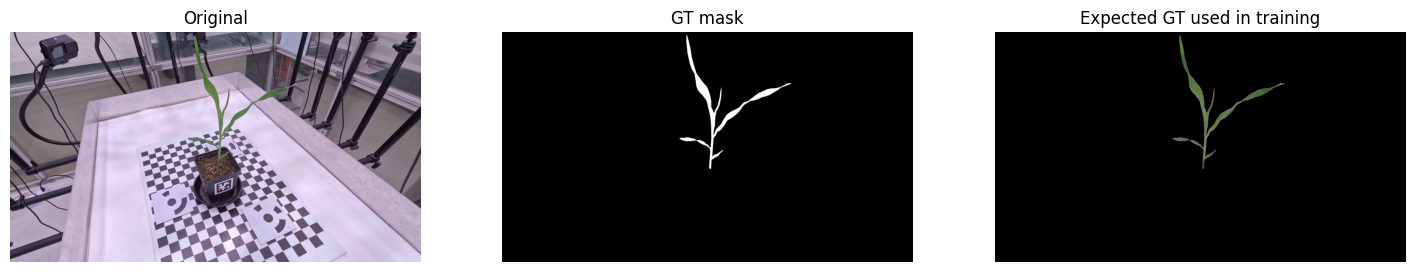

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

images_dir = Path(f"/content/data/{FRAME_NAME}/images")
active_masks_dir = Path(f"/content/data/{FRAME_NAME}/masks_binary_active")

img_path = sorted(images_dir.glob("*.jpg"))[0]
mask_path = active_masks_dir / f"{img_path.stem}_mask_ground_truth.png"

img = np.array(Image.open(img_path).convert("RGB"))
mask = np.array(Image.open(mask_path).convert("L")) > 127

masked_img = img.copy()
masked_img[~mask] = 0

fig, axs = plt.subplots(1, 3, figsize=(18, 6))
axs[0].imshow(img); axs[0].set_title("Original"); axs[0].axis("off")
axs[1].imshow(mask, cmap="gray"); axs[1].set_title("GT mask"); axs[1].axis("off")
axs[2].imshow(masked_img); axs[2].set_title("Expected GT used in training"); axs[2].axis("off")
plt.show()

In [ ]:
%%bash -s "$MODEL_DIR"
set -e

MODEL_DIR="$1"

cd /content/Wheat-3DGS

export CUDA_HOME=/usr/local/cuda
export PATH=$CUDA_HOME/bin:$PATH
export LD_LIBRARY_PATH=$CUDA_HOME/lib64:$LD_LIBRARY_PATH

TORCH_LIB=$(python -c "import os, torch; print(os.path.join(os.path.dirname(torch.__file__), 'lib'))")
export LD_LIBRARY_PATH=$TORCH_LIB:$LD_LIBRARY_PATH

export PYTHONPATH=/content/Wheat-3DGS:/content/Wheat-3DGS/submodules/simple-knn:/content/Wheat-3DGS/submodules/diff-gaussian-rasterization:/content/Wheat-3DGS/submodules/flashsplat-rasterization:$PYTHONPATH

export WANDB_MODE=disabled
export WANDB_DISABLED=true

SCENE="/content/data/frame_1180"
MODEL="$MODEL_DIR"

rm -rf "$MODEL"

python -u train_vanilla_3dgs.py \
  -s "$SCENE" \
  -m "$MODEL" \
  --resolution 4 \
  --iterations 15000

python -u render.py \
  -s "$SCENE" \
  -m "$MODEL" \
  --iteration 15000

Optimizing /content/output/frame_1180_paper_alpha_loss
Output folder: /content/output/frame_1180_paper_alpha_loss [02/04 15:23:21]
No directory of saved bounding boxes found! [02/04 15:23:21]
No directory of saved segmentation masks found! [02/04 15:23:21]
Reading camera 21/21 [02/04 15:23:21]
Train Cam list with 16 cams: ['GX010009_20250825_070502_1880_0', 'GX010030_20250825_070502_1880_1', 'GX010046_20250825_070502_1880_2', 'GX010051_20250825_070502_1880_3', 'GX010059_20250825_070502_1880_4', 'GX010062_20250825_070502_1880_5', 'GX010067_20250825_070502_1880_6', 'GX010068_20250825_070502_1880_7', 'GX010070_20250825_070502_1880_8', 'GX010078_20250825_070502_1880_9', 'GX010081_20250825_070502_1880_10', 'GX010089_20250825_070502_1880_11', 'GX010102_20250825_070502_1880_12', 'GX010127_20250825_070502_1880_13', 'GX010134_20250825_070502_1880_14', 'GX010141_20250825_070502_1880_15'] [02/04 15:23:21]
Test Cam list with 5 cams: ['GX010148_20250825_070503_1880_16', 'GX010156_20250825_070503_18

2026-04-02 15:23:15.629133: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1775143395.650393   15136 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1775143395.657282   15136 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1775143395.675391   15136 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775143395.675414   15136 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775143395.675416   15136 computation_placer.cc:177] computation placer alr

In [ ]:
EXP_NAME = "frame_1180_paper_alpha_loss"
ITERATIONS = 15000
MODEL_DIR = f"/content/output/{EXP_NAME}"

print("EXP_NAME =", EXP_NAME)
print("MODEL_DIR =", MODEL_DIR)

EXP_NAME = frame_1180_paper_alpha_loss
MODEL_DIR = /content/output/frame_1180_paper_alpha_loss


In [ ]:
from PIL import Image
import numpy as np
import os

gt_dir = os.path.join(MODEL_DIR, f"test/ours_{ITERATIONS}/gt")
f = sorted([x for x in os.listdir(gt_dir) if x.endswith(".png")])[0]
img = np.array(Image.open(os.path.join(gt_dir, f)).convert("RGB"))

black_pixels = int(np.sum(np.all(img == 0, axis=2)))
total_pixels = int(img.shape[0] * img.shape[1])

print("first GT file:", f)
print("pure black pixels:", black_pixels)
print("total pixels:", total_pixels)
print("black ratio:", black_pixels / total_pixels)

first GT file: 00000.png
pure black pixels: 15635309
total pixels: 15772800
black ratio: 0.9912830315479814


In [ ]:
import os
import numpy as np
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import torch
import lpips

render_dir = os.path.join(MODEL_DIR, f"test/ours_{ITERATIONS}/renders")
gt_dir = os.path.join(MODEL_DIR, f"test/ours_{ITERATIONS}/gt")

render_files = sorted([f for f in os.listdir(render_dir) if f.endswith(".png")])

psnrs, ssims, lpips_vals = [], [], []
device = "cuda" if torch.cuda.is_available() else "cpu"
loss_fn = lpips.LPIPS(net="vgg").to(device)

for f in render_files:
    render_img = Image.open(os.path.join(render_dir, f)).convert("RGB")
    gt_img = Image.open(os.path.join(gt_dir, f)).convert("RGB")

    render_np = np.array(render_img)
    gt_np = np.array(gt_img)

    psnrs.append(peak_signal_noise_ratio(gt_np, render_np, data_range=255))
    ssims.append(structural_similarity(gt_np, render_np, channel_axis=2, data_range=255))

    render_lp = render_img.resize((512, 512))
    gt_lp = gt_img.resize((512, 512))

    render_t = torch.tensor(np.array(render_lp)).permute(2, 0, 1).float()/127.5 - 1
    gt_t = torch.tensor(np.array(gt_lp)).permute(2, 0, 1).float()/127.5 - 1

    render_t = render_t.unsqueeze(0).to(device)
    gt_t = gt_t.unsqueeze(0).to(device)

    with torch.no_grad():
        lpips_vals.append(loss_fn(render_t, gt_t).item())

mean_psnr = float(np.mean(psnrs))
mean_ssim = float(np.mean(ssims))
mean_lpips = float(np.mean(lpips_vals))

print("\n=== PAPER-STYLE ALPHA LOSS METRICS ===")
print("Mean PSNR :", mean_psnr)
print("Mean SSIM :", mean_ssim)
print("Mean LPIPS:", mean_lpips)

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 241MB/s]


Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/vgg.pth

=== PAPER-STYLE ALPHA LOSS METRICS ===
Mean PSNR : 34.95400516398572
Mean SSIM : 0.9918486203573729
Mean LPIPS: 0.007347320020198822


In [ ]:
from plyfile import PlyData
import os

ply_path = os.path.join(MODEL_DIR, f"point_cloud/iteration_{ITERATIONS}/point_cloud.ply")
ply = PlyData.read(ply_path)
n_gaussians = len(ply["vertex"].data)

metrics_text = f"""Experiment: {EXP_NAME}

Mean PSNR: {mean_psnr}
Mean SSIM: {mean_ssim}
Mean LPIPS: {mean_lpips}
Final gaussians: {n_gaussians}
Black ratio in GT sanity check: {black_pixels / total_pixels}
"""

metrics_path = f"/content/{EXP_NAME}_metrics.txt"
with open(metrics_path, "w") as f:
    f.write(metrics_text)

print("✅ Saved", metrics_path)
print("Final gaussians:", n_gaussians)

✅ Saved /content/frame_1180_paper_alpha_loss_metrics.txt
Final gaussians: 61466


In [ ]:
%%bash -s "$EXP_NAME"
set -e
EXP_NAME="$1"
cd /content
zip -r "${EXP_NAME}.zip" "output/${EXP_NAME}"

  adding: output/frame_1180_paper_alpha_loss/ (stored 0%)
  adding: output/frame_1180_paper_alpha_loss/point_cloud/ (stored 0%)
  adding: output/frame_1180_paper_alpha_loss/point_cloud/iteration_15000/ (stored 0%)
  adding: output/frame_1180_paper_alpha_loss/point_cloud/iteration_15000/point_cloud.ply (deflated 11%)
  adding: output/frame_1180_paper_alpha_loss/point_cloud/iteration_7000/ (stored 0%)
  adding: output/frame_1180_paper_alpha_loss/point_cloud/iteration_7000/point_cloud.ply (deflated 11%)
  adding: output/frame_1180_paper_alpha_loss/events.out.tfevents.1775143401.5ab9d4ef6dbe.15136.0 (deflated 60%)
  adding: output/frame_1180_paper_alpha_loss/cameras.json (deflated 66%)
  adding: output/frame_1180_paper_alpha_loss/input.ply (deflated 48%)
  adding: output/frame_1180_paper_alpha_loss/cfg_args (deflated 28%)
  adding: output/frame_1180_paper_alpha_loss/chkpnt7000.pth (deflated 9%)
  adding: output/frame_1180_paper_alpha_loss/chkpnt15000.pth (deflated 8%)
  adding: output/fram

In [ ]:
from google.colab import files
files.download(f"/content/{EXP_NAME}_metrics.txt")
files.download(f"/content/{EXP_NAME}.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!ls -lah /content/data/frame_1180/sparse/0

total 2.8M
drwxr-xr-x 2 root root 4.0K Apr  2 15:23 .
drwxr-xr-x 3 root root 4.0K Apr  2 15:04 ..
-rw-r--r-- 1 root root   56 Apr  2 15:04 cameras.bin
-rw-r--r-- 1 root root  240 Apr  2 15:04 cameras.txt
-rw-r--r-- 1 root root 527K Apr  2 15:04 images.bin
-rw-r--r-- 1 root root 454K Apr  2 15:04 images.txt
-rw-r--r-- 1 root root 595K Apr  2 15:04 points3D.bin
-rw-r--r-- 1 root root 421K Apr  2 15:23 points3D.ply
-rw-r--r-- 1 root root 789K Apr  2 15:04 points3D.txt


In [ ]:
from pathlib import Path
import shutil

scene_dir = Path("/content/data/frame_1180/sparse/0")
target_ply = scene_dir / "points3D.ply"
backup_ply = scene_dir / "points3D_original_backup.ply"

if not target_ply.exists():
    raise FileNotFoundError(f"Could not find {target_ply}")

if not backup_ply.exists():
    shutil.copy2(target_ply, backup_ply)
    print("✅ Created backup:", backup_ply)
else:
    print("✅ Backup already exists:", backup_ply)

✅ Created backup: /content/data/frame_1180/sparse/0/points3D_original_backup.ply


In [ ]:
import os
import shutil
from pathlib import Path

frame_root = Path(f"/content/data/{FRAME_NAME}")
active = frame_root / "masks_binary_active"
gt = frame_root / "masks_binary_gt"

if active.exists() or active.is_symlink():
    active.unlink() if active.is_symlink() else shutil.rmtree(active)

os.symlink(gt, active, target_is_directory=True)
print("✅ Active masks ->", active.resolve())

✅ Active masks -> /content/data/frame_1180/masks_binary_gt


In [ ]:
!grep -n "masks_binary_active" /content/Wheat-3DGS/scene/dataset_readers.py
!grep -n 'getattr(cam_info, "alpha_mask_path", None)' /content/Wheat-3DGS/utils/camera_utils.py
!grep -n "self.original_image \\*= self.gt_alpha_mask" /content/Wheat-3DGS/scene/cameras.py

107:        alpha_mask_path = os.path.join(os.path.dirname(images_folder), "masks_binary_active", image_name + "_mask_ground_truth.png")
49:    if getattr(cam_info, "alpha_mask_path", None) is not None:
50:        self.original_image *= self.gt_alpha_mask


In [ ]:
from pathlib import Path

path = Path("/content/Wheat-3DGS/arguments/__init__.py")
text = path.read_text()

text = text.replace("self.densify_grad_threshold = 0.0002", "self.densify_grad_threshold = 0.0001")
path.write_text(text)

print("✅ densify_grad_threshold set to 0.0001")

✅ densify_grad_threshold set to 0.0001


In [ ]:
from pathlib import Path
import shutil

scene_dir = Path("/content/data/frame_1180/sparse/0")
ply = scene_dir / "points3D.ply"
backup = scene_dir / "points3D_original_backup.ply"

shutil.copy2(ply, backup)
print("✅ Backup created:", backup)

✅ Backup created: /content/data/frame_1180/sparse/0/points3D_original_backup.ply


In [ ]:
from pathlib import Path

path = Path("/content/Wheat-3DGS/train_vanilla_3dgs.py")
text = path.read_text()

# Remove any previous custom loss injections
text = text.replace("lambda_alpha = 0.01\n", "")
text = text.replace("lambda_mask = 0.01\n", "")

# Inject lambda at top
if "lambda_alpha =" not in text:
    text = "lambda_alpha = 0.01\n" + text

# Replace ONLY the final loss assignment line
lines = text.split("\n")
new_lines = []

for line in lines:
    if "loss =" in line and ("rgb_loss" in line or "Ll1" in line):
        new_lines.append("""        gt_mask = viewpoint_cam.gt_alpha_mask.cuda()
        alpha_map = render_pkg["alpha"]
        if alpha_map.dim() == 2:
            alpha_map = alpha_map.unsqueeze(0)
        alpha_map = alpha_map.clamp(0.0, 1.0)

        alpha_loss = l1_loss(alpha_map, gt_mask)

        loss = rgb_loss + lambda_alpha * alpha_loss""")
    else:
        new_lines.append(line)

text = "\n".join(new_lines)
path.write_text(text)

print("✅ Robust patch applied (paper alpha loss)")

✅ Robust patch applied (paper alpha loss)


In [ ]:
from pathlib import Path

path = Path("/content/Wheat-3DGS/train_vanilla_3dgs.py")
text = path.read_text()

# remove old lambda declarations
for s in [
    "lambda_mask = 0.1\n\n",
    "lambda_mask = 0.01\n\n",
    "lambda_alpha = 0.1\n\n",
    "lambda_alpha = 0.01\n\n",
]:
    text = text.replace(s, "")

# add lambda_alpha
text = text.replace("def training(", f"lambda_alpha = {LAMBDA_ALPHA}\n\ndef training(")

# replace alpha-only block OR silhouette block with paper-alpha block
alpha_block = """        gt_image = viewpoint_cam.original_image.cuda()
        Ll1 = l1_loss(image, gt_image)
        loss = (1.0 - opt.lambda_dssim) * Ll1 + opt.lambda_dssim * (1.0 - ssim(image, gt_image))
"""

silhouette_block = """        gt_image = viewpoint_cam.original_image.cuda()
        gt_mask = viewpoint_cam.gt_alpha_mask.cuda()

        Ll1 = l1_loss(image, gt_image)
        rgb_loss = (1.0 - opt.lambda_dssim) * Ll1 + opt.lambda_dssim * (1.0 - ssim(image, gt_image))

        pred_mask = image.abs().sum(dim=0, keepdim=True)
        pred_mask = pred_mask / (pred_mask.max().detach() + 1e-8)
        pred_mask = pred_mask.clamp(0.0, 1.0)

        mask_loss = l1_loss(pred_mask, gt_mask)

        loss = rgb_loss + lambda_mask * mask_loss
"""

paper_alpha_block = """        gt_image = viewpoint_cam.original_image.cuda()
        gt_mask = viewpoint_cam.gt_alpha_mask.cuda()

        Ll1 = l1_loss(image, gt_image)
        rgb_loss = (1.0 - opt.lambda_dssim) * Ll1 + opt.lambda_dssim * (1.0 - ssim(image, gt_image))

        alpha_map = render_pkg["alpha"]
        if alpha_map.dim() == 2:
            alpha_map = alpha_map.unsqueeze(0)
        alpha_map = alpha_map.clamp(0.0, 1.0)

        alpha_loss = l1_loss(alpha_map, gt_mask)

        loss = rgb_loss + lambda_alpha * alpha_loss
"""

if silhouette_block in text:
    text = text.replace(silhouette_block, paper_alpha_block)
elif alpha_block in text:
    text = text.replace(alpha_block, paper_alpha_block)
else:
    raise ValueError("Could not find a known loss block to replace in train_vanilla_3dgs.py")

path.write_text(text)
print("✅ Patched train_vanilla_3dgs.py to use paper-style alpha loss")

ValueError: Could not find a known loss block to replace in train_vanilla_3dgs.py

In [ ]:
!grep -n "alpha_map" /content/Wheat-3DGS/train_vanilla_3dgs.py
!grep -n "alpha_loss" /content/Wheat-3DGS/train_vanilla_3dgs.py
!grep -n "lambda_alpha" /content/Wheat-3DGS/train_vanilla_3dgs.py

84:        alpha_map = render_pkg["alpha"]
85:        if alpha_map.dim() == 2:
86:            alpha_map = alpha_map.unsqueeze(0)
87:        alpha_map = alpha_map.clamp(0.0, 1.0)
89:        alpha_loss = l1_loss(alpha_map, gt_mask)
93:        alpha_map = render_pkg["alpha"]
94:        if alpha_map.dim() == 2:
95:            alpha_map = alpha_map.unsqueeze(0)
96:        alpha_map = alpha_map.clamp(0.0, 1.0)
98:        alpha_loss = l1_loss(alpha_map, gt_mask)
101:        alpha_map = render_pkg["alpha"]
102:        if alpha_map.dim() == 2:
103:            alpha_map = alpha_map.unsqueeze(0)
104:        alpha_map = alpha_map.clamp(0.0, 1.0)
106:        alpha_loss = l1_loss(alpha_map, gt_mask)
89:        alpha_loss = l1_loss(alpha_map, gt_mask)
91:        loss = rgb_loss + lambda_alpha * alpha_loss
98:        alpha_loss = l1_loss(alpha_map, gt_mask)
106:        alpha_loss = l1_loss(alpha_map, gt_mask)
108:        loss = rgb_loss + lambda_alpha * alpha_loss
1:lambda_alpha = 0.01
91:        loss

In [ ]:
!grep -n "densify_grad_threshold" /content/Wheat-3DGS/arguments/__init__.py
!grep -n "lambda_alpha" /content/Wheat-3DGS/train_vanilla_3dgs.py
!grep -n 'alpha_map = render_pkg\\["alpha"\\]' /content/Wheat-3DGS/train_vanilla_3dgs.py
!grep -n "alpha_loss" /content/Wheat-3DGS/train_vanilla_3dgs.py

88:        self.densify_grad_threshold = 0.0001
1:lambda_alpha = 0.01
91:        loss = rgb_loss + lambda_alpha * alpha_loss
108:        loss = rgb_loss + lambda_alpha * alpha_loss
89:        alpha_loss = l1_loss(alpha_map, gt_mask)
91:        loss = rgb_loss + lambda_alpha * alpha_loss
98:        alpha_loss = l1_loss(alpha_map, gt_mask)
106:        alpha_loss = l1_loss(alpha_map, gt_mask)
108:        loss = rgb_loss + lambda_alpha * alpha_loss


In [ ]:
from pathlib import Path
import re

path = Path("/content/Wheat-3DGS/train_vanilla_3dgs.py")
text = path.read_text()

# 1) remove duplicated lambda declarations at top
text = re.sub(r"^lambda_alpha\s*=\s*0\.01\s*\n+", "", text, flags=re.MULTILINE)

# 2) add exactly one lambda_alpha at the top
text = "lambda_alpha = 0.01\n" + text

# 3) replace the whole training loss snippet between gt_image assignment and loss.backward()
pattern = re.compile(
    r"""
        gt_image\s*=\s*viewpoint_cam\.original_image\.cuda\(\)\n
        .*?
        loss\.backward\(\)
    """,
    re.DOTALL | re.VERBOSE
)

replacement = """        gt_image = viewpoint_cam.original_image.cuda()
        gt_mask = viewpoint_cam.gt_alpha_mask.cuda()

        Ll1 = l1_loss(image, gt_image)
        rgb_loss = (1.0 - opt.lambda_dssim) * Ll1 + opt.lambda_dssim * (1.0 - ssim(image, gt_image))

        alpha_map = render_pkg["alpha"]
        if alpha_map.dim() == 2:
            alpha_map = alpha_map.unsqueeze(0)
        alpha_map = alpha_map.clamp(0.0, 1.0)

        alpha_loss = l1_loss(alpha_map, gt_mask)
        loss = rgb_loss + lambda_alpha * alpha_loss

        loss.backward()"""

matches = list(pattern.finditer(text))
print("matched loss blocks:", len(matches))
if len(matches) != 1:
    raise ValueError(f"Expected exactly 1 training loss block, found {len(matches)}. Stop here and inspect file.")

text = pattern.sub(replacement, text, count=1)
path.write_text(text)

print("✅ train_vanilla_3dgs.py cleaned and patched exactly once")

matched loss blocks: 1
✅ train_vanilla_3dgs.py cleaned and patched exactly once


In [ ]:
!grep -n "lambda_alpha" /content/Wheat-3DGS/train_vanilla_3dgs.py
!grep -n 'alpha_map = render_pkg\["alpha"\]' /content/Wheat-3DGS/train_vanilla_3dgs.py
!grep -n "alpha_loss =" /content/Wheat-3DGS/train_vanilla_3dgs.py
!grep -n "loss = rgb_loss + lambda_alpha \\* alpha_loss" /content/Wheat-3DGS/train_vanilla_3dgs.py

1:lambda_alpha = 0.01
91:        loss = rgb_loss + lambda_alpha * alpha_loss
85:        alpha_map = render_pkg["alpha"]
90:        alpha_loss = l1_loss(alpha_map, gt_mask)
91:        loss = rgb_loss + lambda_alpha * alpha_loss


/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))


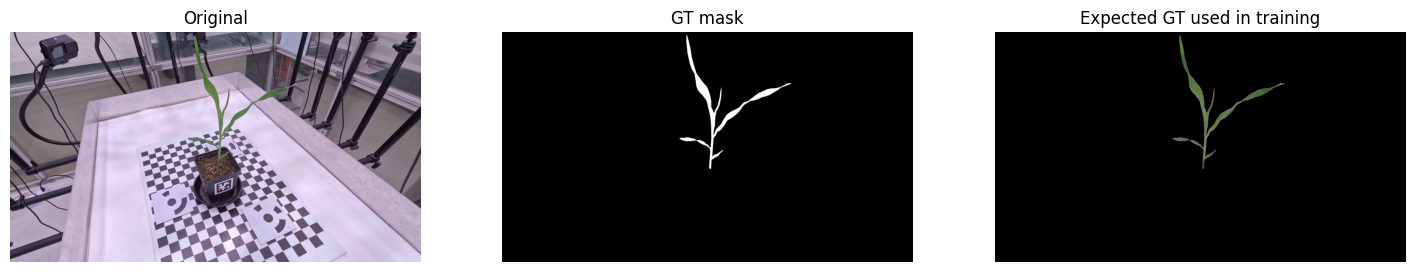

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

images_dir = Path(f"/content/data/{FRAME_NAME}/images")
active_masks_dir = Path(f"/content/data/{FRAME_NAME}/masks_binary_active")

img_path = sorted(images_dir.glob("*.jpg"))[0]
mask_path = active_masks_dir / f"{img_path.stem}_mask_ground_truth.png"

img = np.array(Image.open(img_path).convert("RGB"))
mask = np.array(Image.open(mask_path).convert("L")) > 127

masked_img = img.copy()
masked_img[~mask] = 0

fig, axs = plt.subplots(1, 3, figsize=(18, 6))
axs[0].imshow(img); axs[0].set_title("Original"); axs[0].axis("off")
axs[1].imshow(mask, cmap="gray"); axs[1].set_title("GT mask"); axs[1].axis("off")
axs[2].imshow(masked_img); axs[2].set_title("Expected GT used in training"); axs[2].axis("off")
plt.show()

In [ ]:
EXP_NAME = "frame_1180_paper_alpha_loss_dense"
MODEL_DIR = f"/content/output/{EXP_NAME}"

print("EXP_NAME =", EXP_NAME)
print("MODEL_DIR =", MODEL_DIR)

EXP_NAME = frame_1180_paper_alpha_loss_dense
MODEL_DIR = /content/output/frame_1180_paper_alpha_loss_dense


In [ ]:
%%bash
set -e
cd /content/Wheat-3DGS
git checkout -- train_vanilla_3dgs.py
echo "✅ Restored train_vanilla_3dgs.py from git"

✅ Restored train_vanilla_3dgs.py from git


In [ ]:
from pathlib import Path

path = Path("/content/Wheat-3DGS/train_vanilla_3dgs.py")
lines = path.read_text().splitlines()

for i in range(65, 95):
    print(f"{i+1}: {lines[i]}")

66: 
67:         # Render
68:         if (iteration - 1) == debug_from:
69:             pipe.debug = True
70: 
71:         bg = torch.rand((3), device="cuda") if opt.random_background else background
72: 
73:         render_pkg = render(viewpoint_cam, gaussians, pipe, bg)
74:         image, viewspace_point_tensor, visibility_filter, radii = render_pkg["render"], render_pkg["viewspace_points"], render_pkg["visibility_filter"], render_pkg["radii"]
75: 
76:         # Loss
77:         gt_image = viewpoint_cam.original_image.cuda()
78:         Ll1 = l1_loss(image, gt_image)
79:         loss = (1.0 - opt.lambda_dssim) * Ll1 + opt.lambda_dssim * (1.0 - ssim(image, gt_image))
80:         loss.backward()
81: 
82:         iter_end.record()
83: 
84:         with torch.no_grad():
85:             # Progress bar
86:             ema_loss_for_log = 0.4 * loss.item() + 0.6 * ema_loss_for_log
87:             if iteration % 500 == 0:
88:                 progress_bar.set_postfix({"Loss": f"{ema_loss_for_l

In [ ]:
from pathlib import Path

path = Path("/content/Wheat-3DGS/train_vanilla_3dgs.py")
lines = path.read_text().splitlines()

# Find the start at gt_image assignment
start = None
end = None

for i, line in enumerate(lines):
    if 'gt_image = viewpoint_cam.original_image.cuda()' in line:
        start = i
        break

if start is None:
    raise ValueError("Could not find gt_image line")

for i in range(start, len(lines)):
    if 'loss.backward()' in lines[i]:
        end = i
        break

if end is None:
    raise ValueError("Could not find loss.backward() line")

print("Replacing lines", start+1, "to", end+1)

replacement = [
    '        gt_image = viewpoint_cam.original_image.cuda()',
    '        gt_mask = viewpoint_cam.gt_alpha_mask.cuda()',
    '',
    '        Ll1 = l1_loss(image, gt_image)',
    '        rgb_loss = (1.0 - opt.lambda_dssim) * Ll1 + opt.lambda_dssim * (1.0 - ssim(image, gt_image))',
    '',
    '        alpha_map = render_pkg["alpha"]',
    '        if alpha_map.dim() == 2:',
    '            alpha_map = alpha_map.unsqueeze(0)',
    '        alpha_map = alpha_map.clamp(0.0, 1.0)',
    '',
    '        alpha_loss = l1_loss(alpha_map, gt_mask)',
    '        loss = rgb_loss + lambda_alpha * alpha_loss',
    '',
    '        loss.backward()',
]

new_lines = lines[:start] + replacement + lines[end+1:]

# add lambda_alpha at top if missing
if not any(line.strip() == 'lambda_alpha = 0.01' for line in new_lines[:10]):
    new_lines = ['lambda_alpha = 0.01', ''] + new_lines

path.write_text("\n".join(new_lines) + "\n")
print("✅ Patched cleanly")

Replacing lines 77 to 80
✅ Patched cleanly


In [ ]:
EXP_NAME = "frame_1180_paper_alpha_loss_dense"
MODEL_DIR = f"/content/output/{EXP_NAME}"
ITERATIONS = 15000

print(MODEL_DIR)

/content/output/frame_1180_paper_alpha_loss_dense


In [ ]:
from pathlib import Path

path = Path("/content/Wheat-3DGS/train_vanilla_3dgs.py")
lines = path.read_text().splitlines()

for i in range(1, 15):
    print(f"{i}: {lines[i-1]}")

print("\n--- loss block ---")
for i in range(70, 95):
    print(f"{i+1}: {lines[i]}")

1: lambda_alpha = 0.01
2: 
3: #
4: # Copyright (C) 2023, Inria
5: # GRAPHDECO research group, https://team.inria.fr/graphdeco
6: # All rights reserved.
7: #
8: # This software is free for non-commercial, research and evaluation use 
9: # under the terms of the LICENSE.md file.
10: #
11: # For inquiries contact  george.drettakis@inria.fr
12: #
13: 
14: import os

--- loss block ---
71:             pipe.debug = True
72: 
73:         bg = torch.rand((3), device="cuda") if opt.random_background else background
74: 
75:         render_pkg = render(viewpoint_cam, gaussians, pipe, bg)
76:         image, viewspace_point_tensor, visibility_filter, radii = render_pkg["render"], render_pkg["viewspace_points"], render_pkg["visibility_filter"], render_pkg["radii"]
77: 
78:         # Loss
79:         gt_image = viewpoint_cam.original_image.cuda()
80:         gt_mask = viewpoint_cam.gt_alpha_mask.cuda()
81: 
82:         Ll1 = l1_loss(image, gt_image)
83:         rgb_loss = (1.0 - opt.lambda_dssim) * 

In [ ]:
%%bash -s "$MODEL_DIR"
set -e

MODEL_DIR="$1"

cd /content/Wheat-3DGS

export CUDA_HOME=/usr/local/cuda
export PATH=$CUDA_HOME/bin:$PATH
export LD_LIBRARY_PATH=$CUDA_HOME/lib64:$LD_LIBRARY_PATH

TORCH_LIB=$(python -c "import os, torch; print(os.path.join(os.path.dirname(torch.__file__), 'lib'))")
export LD_LIBRARY_PATH=$TORCH_LIB:$LD_LIBRARY_PATH

export PYTHONPATH=/content/Wheat-3DGS:/content/Wheat-3DGS/submodules/simple-knn:/content/Wheat-3DGS/submodules/diff-gaussian-rasterization:/content/Wheat-3DGS/submodules/flashsplat-rasterization:$PYTHONPATH

export WANDB_MODE=disabled
export WANDB_DISABLED=true

SCENE="/content/data/frame_1180"
MODEL="$MODEL_DIR"

rm -rf "$MODEL"

python -u train_vanilla_3dgs.py \
  -s "$SCENE" \
  -m "$MODEL" \
  --resolution 4 \
  --iterations 15000

python -u render.py \
  -s "$SCENE" \
  -m "$MODEL" \
  --iteration 15000

Optimizing /content/output/frame_1180_paper_alpha_loss_dense
Output folder: /content/output/frame_1180_paper_alpha_loss_dense [02/04 15:58:16]
No directory of saved bounding boxes found! [02/04 15:58:16]
No directory of saved segmentation masks found! [02/04 15:58:16]
Reading camera 21/21 [02/04 15:58:16]
Train Cam list with 16 cams: ['GX010009_20250825_070502_1880_0', 'GX010030_20250825_070502_1880_1', 'GX010046_20250825_070502_1880_2', 'GX010051_20250825_070502_1880_3', 'GX010059_20250825_070502_1880_4', 'GX010062_20250825_070502_1880_5', 'GX010067_20250825_070502_1880_6', 'GX010068_20250825_070502_1880_7', 'GX010070_20250825_070502_1880_8', 'GX010078_20250825_070502_1880_9', 'GX010081_20250825_070502_1880_10', 'GX010089_20250825_070502_1880_11', 'GX010102_20250825_070502_1880_12', 'GX010127_20250825_070502_1880_13', 'GX010134_20250825_070502_1880_14', 'GX010141_20250825_070502_1880_15'] [02/04 15:58:16]
Test Cam list with 5 cams: ['GX010148_20250825_070503_1880_16', 'GX010156_202508

2026-04-02 15:58:10.881108: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1775145490.901839   24433 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1775145490.908924   24433 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1775145490.927743   24433 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775145490.927773   24433 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775145490.927775   24433 computation_placer.cc:177] computation placer alr

In [ ]:
import os
import numpy as np
from PIL import Image

gt_dir = f"/content/output/{EXP_NAME}/test/ours_{ITERATIONS}/gt"
print("gt_dir exists:", os.path.exists(gt_dir))
print("files:", sorted(os.listdir(gt_dir))[:5])

f = sorted([x for x in os.listdir(gt_dir) if x.endswith(".png")])[0]
img = np.array(Image.open(os.path.join(gt_dir, f)).convert("RGB"))
black_ratio = np.mean(np.all(img == 0, axis=2))
print("black ratio:", black_ratio)

gt_dir exists: True
files: ['00000.png', '00001.png', '00002.png', '00003.png', '00004.png']
black ratio: 0.9912830315479814


first GT file: 00000.png
pure black pixels: 15635309
total pixels: 15772800
black ratio: 0.9912830315479814


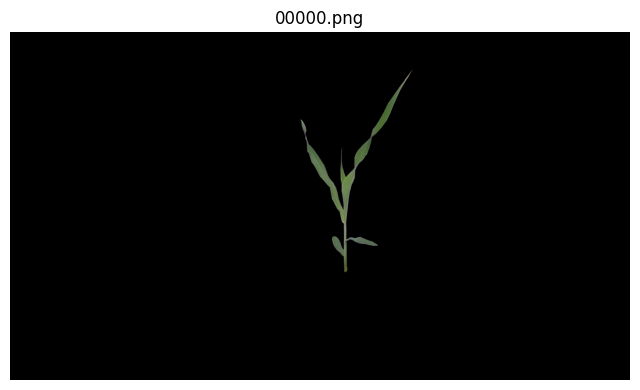

In [ ]:
from PIL import Image
import numpy as np
import os
import matplotlib.pyplot as plt

gt_dir = os.path.join(MODEL_DIR, f"test/ours_{ITERATIONS}/gt")
f = sorted([x for x in os.listdir(gt_dir) if x.endswith(".png")])[0]
img = np.array(Image.open(os.path.join(gt_dir, f)).convert("RGB"))

black_pixels = int(np.sum(np.all(img == 0, axis=2)))
total_pixels = int(img.shape[0] * img.shape[1])

print("first GT file:", f)
print("pure black pixels:", black_pixels)
print("total pixels:", total_pixels)
print("black ratio:", black_pixels / total_pixels)

plt.figure(figsize=(8,6))
plt.imshow(img)
plt.title(f)
plt.axis("off")
plt.show()

In [ ]:
import os
import numpy as np
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import torch
import lpips

render_dir = os.path.join(MODEL_DIR, f"test/ours_{ITERATIONS}/renders")
gt_dir = os.path.join(MODEL_DIR, f"test/ours_{ITERATIONS}/gt")

render_files = sorted([f for f in os.listdir(render_dir) if f.endswith(".png")])

psnrs, ssims, lpips_vals = [], [], []
device = "cuda" if torch.cuda.is_available() else "cpu"
loss_fn = lpips.LPIPS(net="vgg").to(device)

for f in render_files:
    render_img = Image.open(os.path.join(render_dir, f)).convert("RGB")
    gt_img = Image.open(os.path.join(gt_dir, f)).convert("RGB")

    render_np = np.array(render_img)
    gt_np = np.array(gt_img)

    psnrs.append(peak_signal_noise_ratio(gt_np, render_np, data_range=255))
    ssims.append(structural_similarity(gt_np, render_np, channel_axis=2, data_range=255))

    render_lp = render_img.resize((512, 512))
    gt_lp = gt_img.resize((512, 512))

    render_t = torch.tensor(np.array(render_lp)).permute(2, 0, 1).float()/127.5 - 1
    gt_t = torch.tensor(np.array(gt_lp)).permute(2, 0, 1).float()/127.5 - 1

    render_t = render_t.unsqueeze(0).to(device)
    gt_t = gt_t.unsqueeze(0).to(device)

    with torch.no_grad():
        lpips_vals.append(loss_fn(render_t, gt_t).item())

mean_psnr = float(np.mean(psnrs))
mean_ssim = float(np.mean(ssims))
mean_lpips = float(np.mean(lpips_vals))

print("\n=== PAPER-ALPHA + DENSE METRICS ===")
print("Mean PSNR :", mean_psnr)
print("Mean SSIM :", mean_ssim)
print("Mean LPIPS:", mean_lpips)

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]
Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/vgg.pth

=== PAPER-ALPHA + DENSE METRICS ===
Mean PSNR : 34.86614377795195
Mean SSIM : 0.9915110929620237
Mean LPIPS: 0.007890604436397552


In [ ]:
from plyfile import PlyData
import os

ply_path = os.path.join(MODEL_DIR, f"point_cloud/iteration_{ITERATIONS}/point_cloud.ply")
ply = PlyData.read(ply_path)
n_gaussians = len(ply["vertex"].data)

metrics_text = f"""Experiment: {EXP_NAME}

Mean PSNR: {mean_psnr}
Mean SSIM: {mean_ssim}
Mean LPIPS: {mean_lpips}
Final gaussians: {n_gaussians}
Black ratio in GT sanity check: {black_pixels / total_pixels}
"""

metrics_path = f"/content/{EXP_NAME}_metrics.txt"
with open(metrics_path, "w") as f:
    f.write(metrics_text)

print("✅ Saved", metrics_path)
print("Final gaussians:", n_gaussians)

✅ Saved /content/frame_1180_paper_alpha_loss_dense_metrics.txt
Final gaussians: 110853


In [ ]:
%%bash -s "$EXP_NAME"
set -e
EXP_NAME="$1"
cd /content
zip -r "${EXP_NAME}.zip" "output/${EXP_NAME}"

  adding: output/frame_1180_paper_alpha_loss_dense/ (stored 0%)
  adding: output/frame_1180_paper_alpha_loss_dense/point_cloud/ (stored 0%)
  adding: output/frame_1180_paper_alpha_loss_dense/point_cloud/iteration_15000/ (stored 0%)
  adding: output/frame_1180_paper_alpha_loss_dense/point_cloud/iteration_15000/point_cloud.ply (deflated 11%)
  adding: output/frame_1180_paper_alpha_loss_dense/point_cloud/iteration_7000/ (stored 0%)
  adding: output/frame_1180_paper_alpha_loss_dense/point_cloud/iteration_7000/point_cloud.ply (deflated 11%)
  adding: output/frame_1180_paper_alpha_loss_dense/events.out.tfevents.1775145496.5ab9d4ef6dbe.24433.0 (deflated 60%)
  adding: output/frame_1180_paper_alpha_loss_dense/cameras.json (deflated 66%)
  adding: output/frame_1180_paper_alpha_loss_dense/input.ply (deflated 48%)
  adding: output/frame_1180_paper_alpha_loss_dense/cfg_args (deflated 28%)
  adding: output/frame_1180_paper_alpha_loss_dense/chkpnt7000.pth (deflated 10%)
  adding: output/frame_1180_p

In [ ]:
from google.colab import files
files.download(f"/content/{EXP_NAME}_metrics.txt")
files.download(f"/content/{EXP_NAME}.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>